# Extended Results Comparison

Evaluate the saved extended forecasts without fitting models. Results remain separate for each country, origin and horizon. Compare model errors with Naive within HS chapters, import/export flows and frozen size classes. Pooled scores are not used as the primary comparison.

All tables and figures are saved alongside the keyed predictions in results/extended_benchmark/. The original March, REER and Suez results are not read as new experiment predictions or overwritten.

## 1. Load the Completed Experiment

Require all seven models at every agreed origin and horizon. Run identifiers connect predictions and model settings. Process one country at a time to limit memory. Partial Parquet files are never used.

In [1]:
from pathlib import Path
import sys,gc
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from IPython.display import display
PROJECT_ROOT=Path.cwd()
if PROJECT_ROOT.name=='notebooks':PROJECT_ROOT=PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:sys.path.insert(0,str(PROJECT_ROOT))
from src.dataset_loading import COUNTRY_PREFIXES,SERIES_KEYS
from src.evaluation import evaluate_forecasts
OUTPUT_DIR=PROJECT_ROOT/'results'/'extended_benchmark'
PREDICTION_PATH=OUTPUT_DIR/'predictions.parquet'
MODELS=['Naive','Seasonal Naive','ETS','ARIMA','XGBoost','LSTM','Chronos']
COUNTRIES=list(COUNTRY_PREFIXES)
ORIGINS=pd.to_datetime(['2025-04-01','2025-08-01','2025-12-01'])
HORIZONS=[1,2,3]
METRICS=['MAE','RMSE','sMAPE (%)']
MIN_GROUP_SERIES=30
GROUP_COLUMNS={'HSChapter':'HSChapter','Flow':'TradeFlow','SizeClass':'SizeClass'}
COLORS=dict(zip(MODELS,['#777777','#b7bdc4','#2374ab','#149fad','#e1812c','#8663ae','#2f8a59']))
assert PREDICTION_PATH.is_file(),'A complete notebook 16 run is required.'
settings=pd.read_csv(OUTPUT_DIR/'model_settings.csv',dtype={'RunID':str})
for column in ['Origin','TargetMonth','FitThrough','CohortCutoff','SelectionOrigin',
               'EpochValidationOrigin','EpochValidationTarget']:
    settings[column]=pd.to_datetime(settings[column])
assert len(settings)==len(COUNTRIES)*len(MODELS)*len(ORIGINS)*len(HORIZONS)
assert not settings.duplicated(['Country','Model','Origin','Horizon']).any()
assert settings.RunID.nunique()==1
RUN_ID=settings.RunID.iloc[0]
assert settings.CohortCutoff.eq(pd.Timestamp('2024-12-01')).all()
assert settings.SelectionOrigin.eq(pd.Timestamp('2024-12-01')).all()
learned=settings.loc[settings.Model.isin(['XGBoost','LSTM'])]
assert learned.groupby(['Country','Model','Horizon']).Configuration.nunique().eq(1).all()
lstm=settings.loc[settings.Model.eq('LSTM')]
assert lstm.EpochValidationTarget.eq(lstm.Origin).all()
assert lstm.Epochs.between(1,15).all()
assert all(row.EpochValidationOrigin+pd.DateOffset(months=int(row.Horizon))==row.Origin
           for row in lstm.itertuples())
chronos=settings.loc[settings.Model.eq('Chronos')]
assert chronos.Checkpoint.eq('amazon/chronos-bolt-tiny').all()
assert chronos.CheckpointRevision.eq('f6ff2d2ba9168d498c015bc8dd07e3b395b31b3f').all()
with duckdb.connect() as con:
    assert set(con.execute('SELECT DISTINCT Country FROM read_parquet(?)',[str(PREDICTION_PATH)]).df().Country)==set(COUNTRIES)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,
                     'axes.grid':True,'grid.alpha':.2,'axes.axisbelow':True})
print('Completed run:',RUN_ID)
display(settings[['Country','Model','Origin','Horizon','Configuration','Epochs','Fallbacks','Device']])

Completed run: 9af9c19e93e8486d9aaa821a50854c11


,Country,Model,Origin,Horizon,Configuration,Epochs,Fallbacks,Device
0,South Korea,Naive,2025-04-01,1,last_value,NaN,0,cpu
1,South Korea,Seasonal Naive,2025-04-01,1,same_month_last_year,NaN,0,cpu
2,South Korea,Naive,2025-04-01,2,last_value,NaN,0,cpu
3,South Korea,Seasonal Naive,2025-04-01,2,same_month_last_year,NaN,0,cpu
4,South Korea,Naive,2025-04-01,3,last_value,NaN,0,cpu
...,...,...,...,...,...,...,...,...
184,USA,XGBoost,2025-12-01,3,XGBoost_3,NaN,0,cpu
185,USA,LSTM,2025-12-01,3,LSTM_2,5.0,0,cpu
186,USA,Chronos,2025-12-01,1,Chronos-Bolt Tiny,NaN,0,cpu
187,USA,Chronos,2025-12-01,2,Chronos-Bolt Tiny,NaN,0,cpu


## 2. Verify Matched Series and Calculate Errors

Compare full series keys, actual values and source flags against Naive, rather than checking counts alone. Groups must remain unchanged across all origins and horizons. No series is excluded for poor fit or later inactivity; fallbacks and zero-completed targets remain visible.

Use the project's MAE, RMSE and sMAPE implementation. Group results describe each dimension separately, not intersections of chapter, flow and size. A group with fewer than 30 series is flagged for caution, not removed.

In [2]:
PAIR_KEYS=SERIES_KEYS+['Origin','Horizon','TargetMonth']
def validate_country(frame,country):
    assert set(frame.Model)==set(MODELS) and frame.Country.eq(country).all()
    assert frame.RunID.eq(RUN_ID).all()
    assert frame.CohortCutoff.eq(pd.Timestamp('2024-12-01')).all()
    assert not frame.duplicated(['Model']+PAIR_KEYS).any()
    assert np.isfinite(frame[['Value','Prediction']]).all().all()
    assert frame.Value.ge(0).all()
    assert set(frame.Origin)==set(ORIGINS) and set(frame.Horizon)==set(HORIZONS)
    assert all(o+pd.DateOffset(months=int(h))==t for o,h,t in
               frame[['Origin','Horizon','TargetMonth']].drop_duplicates().itertuples(index=False,name=None))
    reference=frame.loc[frame.Model.eq('Naive')].sort_values(PAIR_KEYS).reset_index(drop=True)
    frozen=reference[SERIES_KEYS+['HSChapter','SizeClass','HistoricalMean']].drop_duplicates()
    assert not frozen.duplicated(SERIES_KEYS).any()
    n=len(frozen)
    for (origin,h),group in reference.groupby(['Origin','Horizon']):
        pd.testing.assert_frame_equal(group[SERIES_KEYS].sort_values(SERIES_KEYS).reset_index(drop=True),
                                      frozen[SERIES_KEYS].sort_values(SERIES_KEYS).reset_index(drop=True))
        assert len(group)==n
    compare=PAIR_KEYS+['Value','SourceObserved','HSChapter','SizeClass','HistoricalMean']
    for model in MODELS:
        candidate=frame.loc[frame.Model.eq(model)].sort_values(PAIR_KEYS).reset_index(drop=True)
        pd.testing.assert_frame_equal(candidate[compare],reference[compare])
        assert len(candidate)==n*len(ORIGINS)*len(HORIZONS)
        recorded=settings.loc[settings.Country.eq(country)&settings.Model.eq(model)]
        assert recorded['N Series'].eq(n).all()
        actual_counts=candidate.groupby(['Origin','Horizon']).Fallback.sum().sort_index()
        saved_counts=recorded.set_index(['Origin','Horizon']).Fallbacks.sort_index()
        np.testing.assert_array_equal(actual_counts.to_numpy(),saved_counts.to_numpy())
    return n

def metric_record(country,model,origin,h,group):
    result=evaluate_forecasts(country,model,group.Value,group.Prediction,
                              group.TargetMonth.iloc[0].strftime('%Y-%m'))
    result.update({'RunID':RUN_ID,'Origin':origin,'Horizon':int(h),
        'N Observations':len(group),'Fallbacks':int(group.Fallback.sum()),
        'NegativeForecasts':int(group.Prediction.lt(0).sum()),
        'ZeroCompletedTargets':int((~group.SourceObserved).sum())})
    return result

origin_rows=[];group_rows=[];cohort_counts=[]
for country in COUNTRIES:
    frame=pd.read_parquet(PREDICTION_PATH,filters=[('Country','==',country)])
    n=validate_country(frame,country)
    cohort_counts.append({'Country':country,'N Series':n,'PredictionRows':len(frame)})
    for (model,origin,h),group in frame.groupby(['Model','Origin','Horizon'],observed=True):
        origin_rows.append(metric_record(country,model,origin,h,group))
        for group_type,column in GROUP_COLUMNS.items():
            for label,part in group.groupby(column,observed=True):
                result=metric_record(country,model,origin,h,part)
                result.update({'GroupType':group_type,'Group':str(label),'SmallGroup':len(part)<MIN_GROUP_SERIES})
                group_rows.append(result)
    del frame
    gc.collect()
origin_metrics=pd.DataFrame(origin_rows)
group_metrics=pd.DataFrame(group_rows)
assert len(origin_metrics)==len(COUNTRIES)*len(MODELS)*len(ORIGINS)*len(HORIZONS)
display(pd.DataFrame(cohort_counts))

,Country,N Series,PredictionRows
0,South Korea,28231,1778553
1,Slovakia,31328,1973664
2,USA,39739,2503557


## 3. Comparison with Naive

Relative improvement is 100 × (Naive error − model error) / Naive error. Positive values indicate better accuracy than Naive; negative values indicate higher error. Calculate the reference within the exact same country, origin, horizon and group. A zero Naive error gives an undefined relative improvement, recorded as missing rather than infinity.

Save primary origin-specific metrics and all group breakdowns. No averaging across origins is required for these comparisons.

In [3]:
def add_naive_comparison(table,keys):
    reference=table.loc[table.Model.eq('Naive'),keys+METRICS].rename(
        columns={m:'Naive '+m for m in METRICS})
    result=table.merge(reference,on=keys,validate='many_to_one')
    for metric in METRICS:
        denominator=result['Naive '+metric]
        result[metric+' improvement (%)']=100*(denominator-result[metric])/denominator.replace(0,np.nan)
        label='sMAPE difference (pp)' if metric=='sMAPE (%)' else metric+' difference'
        result[label]=result[metric]-denominator
        result[metric+' zero Naive error']=denominator.eq(0)
    return result
base=['Country','Origin','Horizon']
origin_metrics=add_naive_comparison(origin_metrics,base).sort_values(base+['Model'])
group_metrics=add_naive_comparison(group_metrics,base+['GroupType','Group']).sort_values(
    base+['GroupType','Group','Model'])
origin_metrics.to_csv(OUTPUT_DIR/'origin_metrics.csv',index=False)
group_metrics.to_csv(OUTPUT_DIR/'group_metrics.csv',index=False)
display(origin_metrics[['Country','Model','Origin','Horizon','N Series']+METRICS+['sMAPE (%) improvement (%)']])
display(group_metrics[['Country','Origin','Horizon','GroupType','Group','N Series','SmallGroup']].drop_duplicates())

,Country,Model,Origin,Horizon,N Series,MAE,RMSE,sMAPE (%),sMAPE (%) improvement (%)
63,Slovakia,ARIMA,2025-04-01,1,31328,1.322050e+05,1.606930e+06,110.222625,-59.954613
72,Slovakia,Chronos,2025-04-01,1,31328,1.192463e+05,1.430755e+06,97.199029,-41.054825
81,Slovakia,ETS,2025-04-01,1,31328,1.317424e+05,1.469403e+06,112.757046,-63.632555
90,Slovakia,LSTM,2025-04-01,1,31328,1.403699e+05,1.614488e+06,113.790960,-65.132967
99,Slovakia,Naive,2025-04-01,1,31328,1.461993e+05,1.791400e+06,68.908687,0.000000
...,...,...,...,...,...,...,...,...,...
152,USA,ETS,2025-12-01,3,39739,2.961184e+06,4.213998e+07,90.314544,-31.130919
161,USA,LSTM,2025-12-01,3,39739,4.074585e+06,8.239057e+07,99.022032,-43.773633
170,USA,Naive,2025-12-01,3,39739,3.109090e+06,4.271017e+07,68.873569,0.000000
179,USA,Seasonal Naive,2025-12-01,3,39739,5.577915e+06,1.286121e+08,72.924873,-5.882233


,Country,Origin,Horizon,GroupType,Group,N Series,SmallGroup
6523,Slovakia,2025-04-01,1,Flow,export,14503,False
6524,Slovakia,2025-04-01,1,Flow,import,16825,False
6426,Slovakia,2025-04-01,1,HSChapter,01,90,False
6427,Slovakia,2025-04-01,1,HSChapter,02,181,False
6428,Slovakia,2025-04-01,1,HSChapter,03,124,False
...,...,...,...,...,...,...,...
13772,USA,2025-12-01,3,HSChapter,98,180,False
13773,USA,2025-12-01,3,HSChapter,99,40,False
13776,USA,2025-12-01,3,SizeClass,Large,13246,False
13777,USA,2025-12-01,3,SizeClass,Medium,13246,False


## 4. Accuracy by Horizon and Origin

The horizon figure has one panel per country and origin, with horizons 1–3 on the horizontal axis. The origin figure has one panel per country and horizon. Both display the same origin-specific sMAPE scores from different perspectives, using a common vertical scale. Neither pools forecast origins.

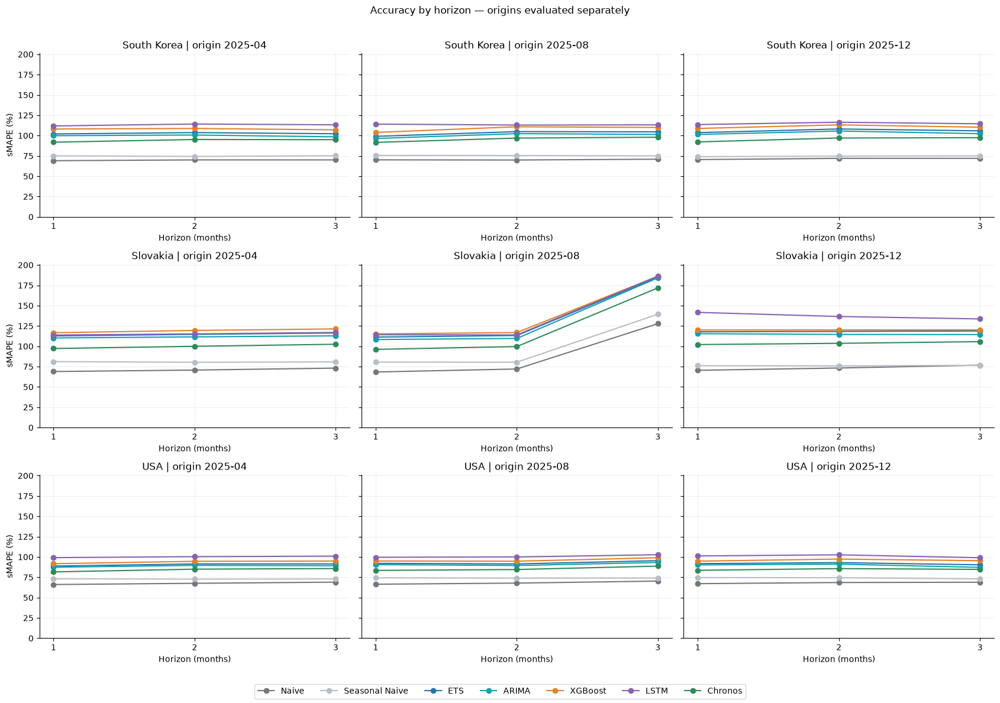

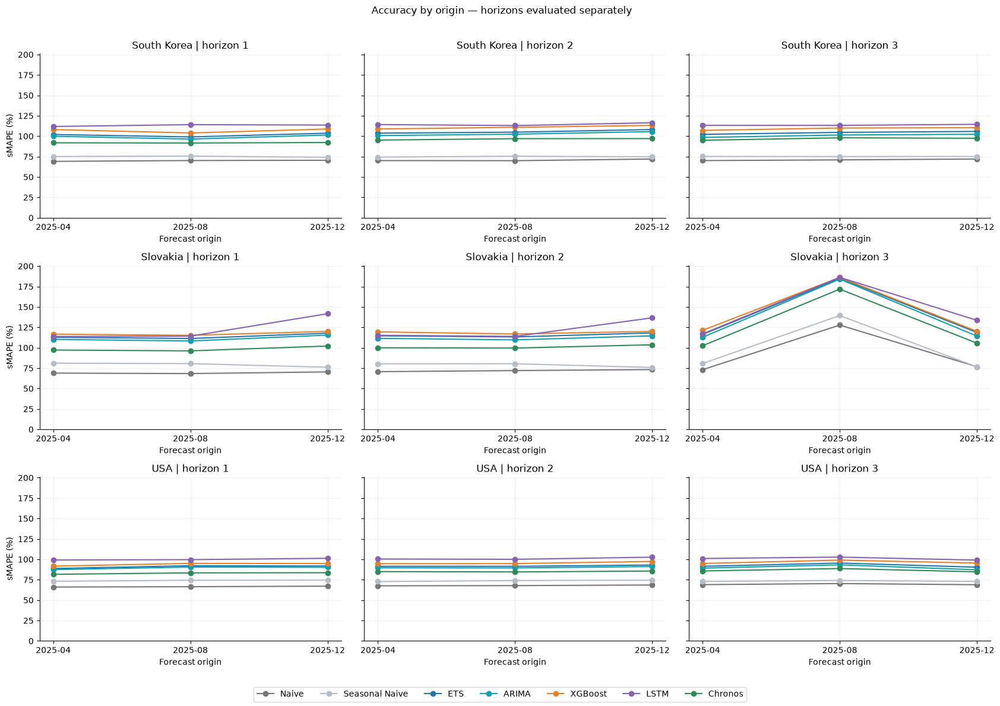

In [4]:
upper=max(1,float(origin_metrics['sMAPE (%)'].max())*1.08)
fig,axes=plt.subplots(len(COUNTRIES),len(ORIGINS),figsize=(17,12),sharey=True)
for row,country in enumerate(COUNTRIES):
    for col,origin in enumerate(ORIGINS):
        ax=axes[row,col]
        for model in MODELS:
            group=origin_metrics.loc[origin_metrics.Country.eq(country)&origin_metrics.Origin.eq(origin)&
                                      origin_metrics.Model.eq(model)].sort_values('Horizon')
            ax.plot(group.Horizon,group['sMAPE (%)'],marker='o',color=COLORS[model],label=model)
        ax.set_title(f'{country} | origin {origin:%Y-%m}')
        ax.set_xticks(HORIZONS);ax.set_xlabel('Horizon (months)');ax.set_ylim(0,upper)
        if col==0:ax.set_ylabel('sMAPE (%)')
handles,labels=axes[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='lower center',ncols=len(MODELS))
fig.suptitle('Accuracy by horizon — origins evaluated separately')
fig.tight_layout(rect=[0,.04,1,.97])
fig.savefig(OUTPUT_DIR/'accuracy_by_horizon.png',dpi=150,bbox_inches='tight')
display(fig);plt.close(fig)

fig,axes=plt.subplots(len(COUNTRIES),len(HORIZONS),figsize=(17,12),sharey=True)
for row,country in enumerate(COUNTRIES):
    for col,h in enumerate(HORIZONS):
        ax=axes[row,col]
        for model in MODELS:
            group=origin_metrics.loc[origin_metrics.Country.eq(country)&origin_metrics.Horizon.eq(h)&
                                      origin_metrics.Model.eq(model)].sort_values('Origin')
            ax.plot(range(len(ORIGINS)),group['sMAPE (%)'],marker='o',color=COLORS[model],label=model)
        ax.set_title(f'{country} | horizon {h}')
        ax.set_xticks(range(len(ORIGINS)),[o.strftime('%Y-%m') for o in ORIGINS])
        ax.set_xlabel('Forecast origin');ax.set_ylim(0,upper)
        if col==0:ax.set_ylabel('sMAPE (%)')
fig.legend(handles,labels,loc='lower center',ncols=len(MODELS))
fig.suptitle('Accuracy by origin — horizons evaluated separately')
fig.tight_layout(rect=[0,.04,1,.97])
fig.savefig(OUTPUT_DIR/'accuracy_by_origin.png',dpi=150,bbox_inches='tight')
display(fig);plt.close(fig)

## 5. Product, Flow and Size Accuracy

Each country-origin figure has three horizon panels. Rows identify HS chapters, flows or size classes and their series counts; columns identify the six alternatives to Naive. Plot sMAPE improvement relative to Naive: green is better, red worse. All numerical MAE and RMSE comparisons remain in group_metrics.csv.

Colour is limited to ±100% for readability; labels retain actual values outside that range. Undefined improvements appear as N/A. Asterisks identify groups with fewer than 30 series; they are retained. Save each country and origin separately to keep all HS chapters legible. No top-product filtering or cross-origin averaging is applied.

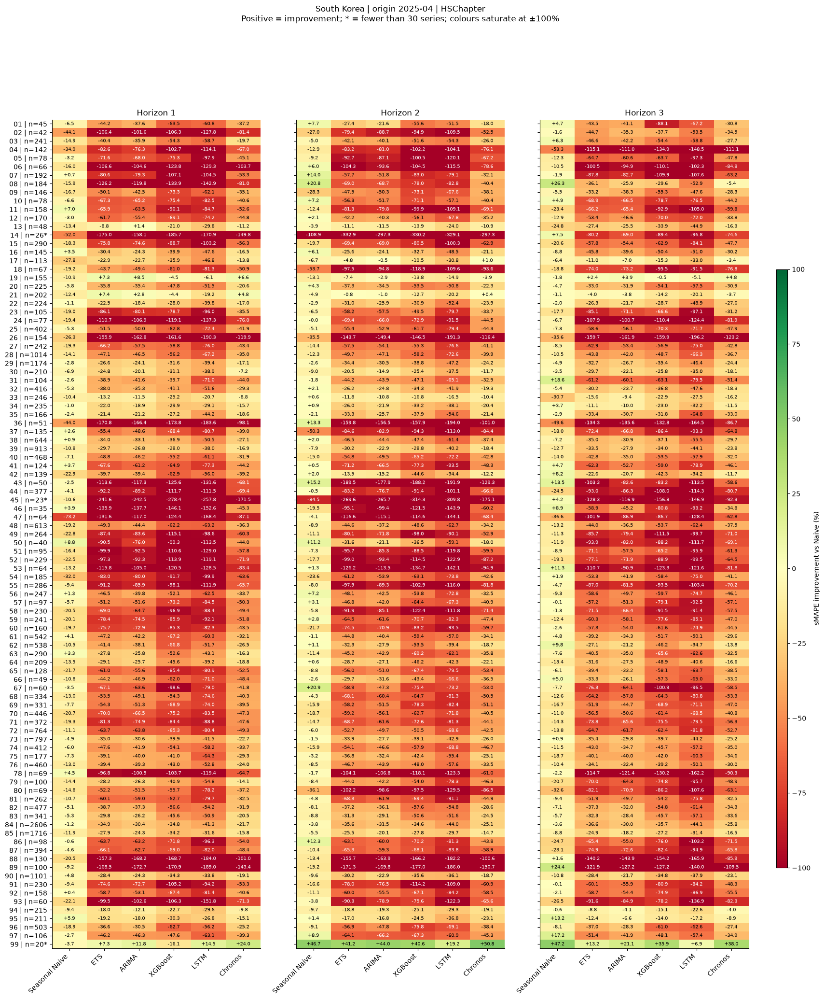

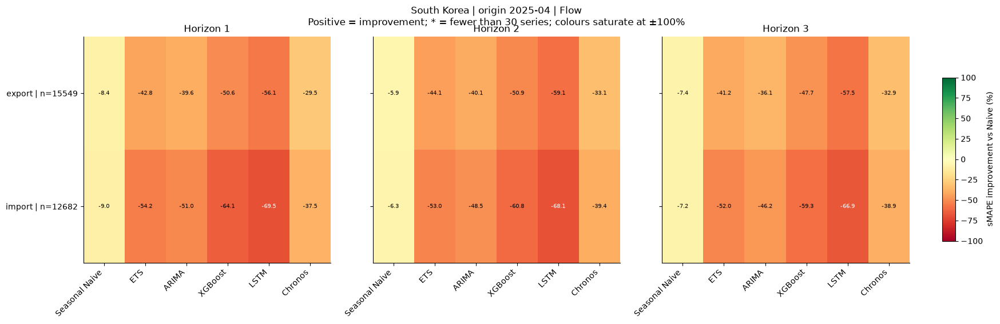

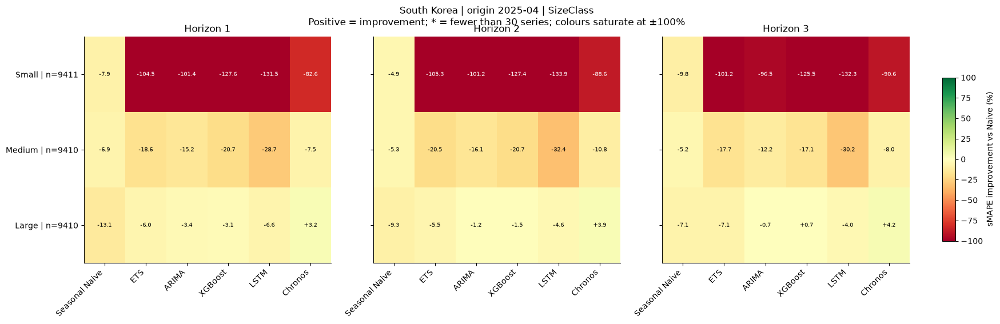

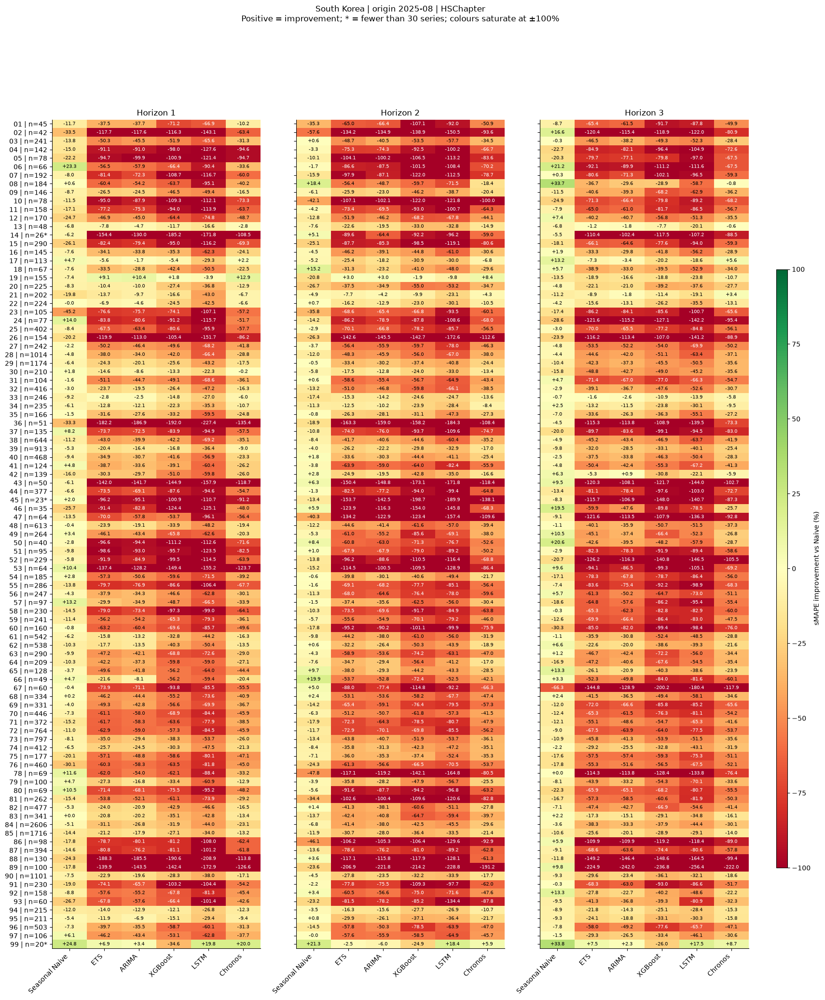

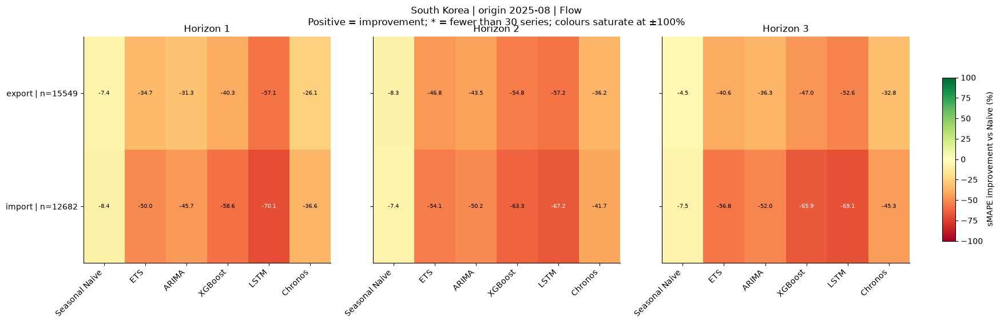

...

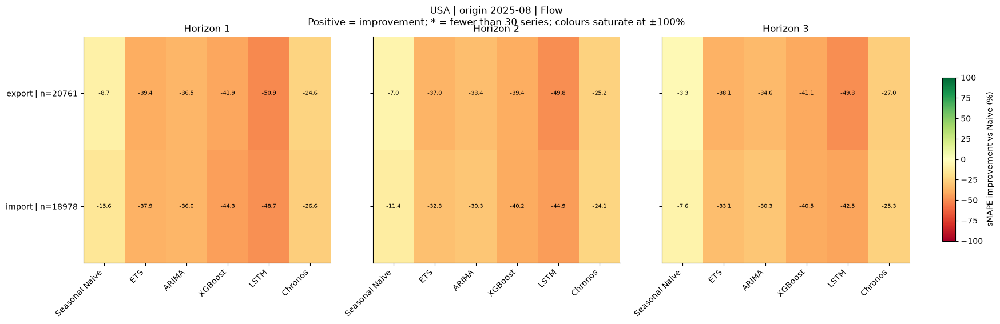

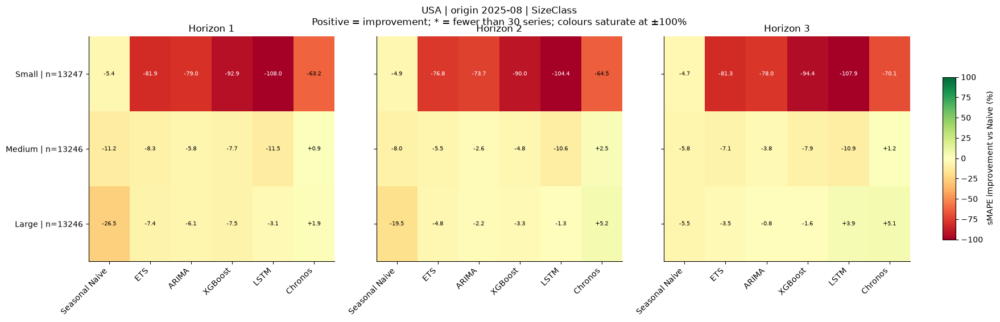

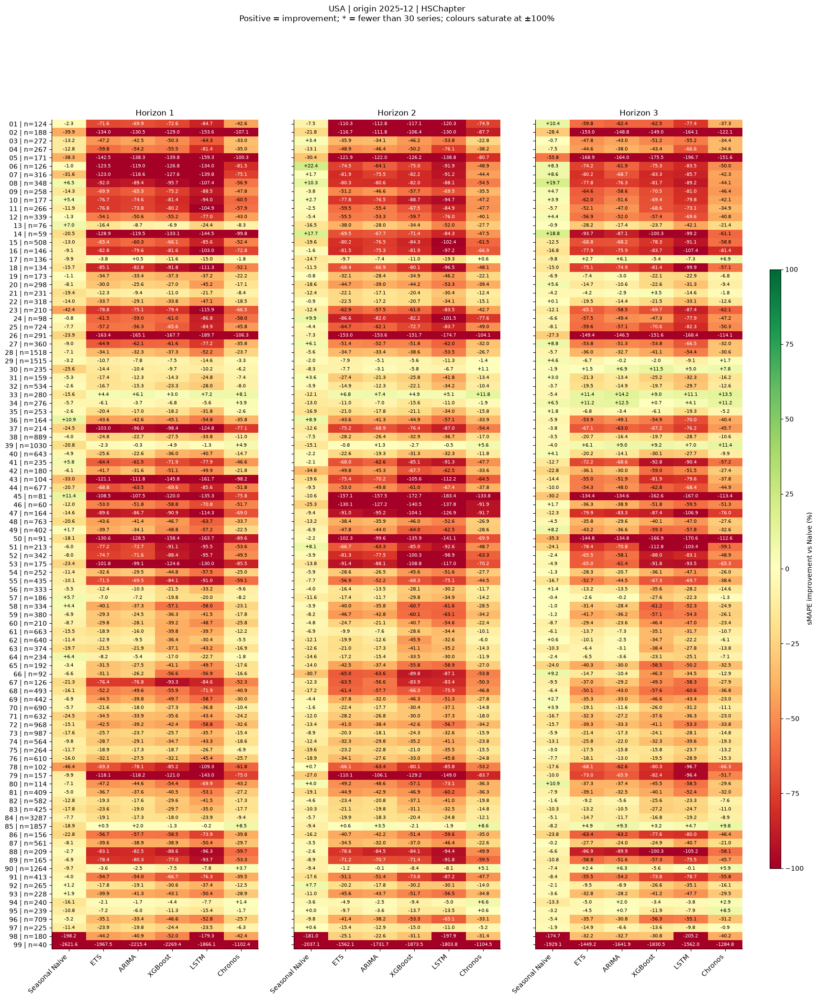

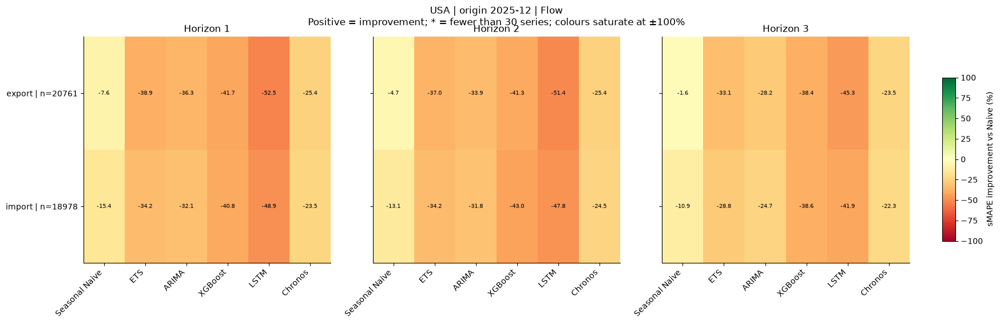

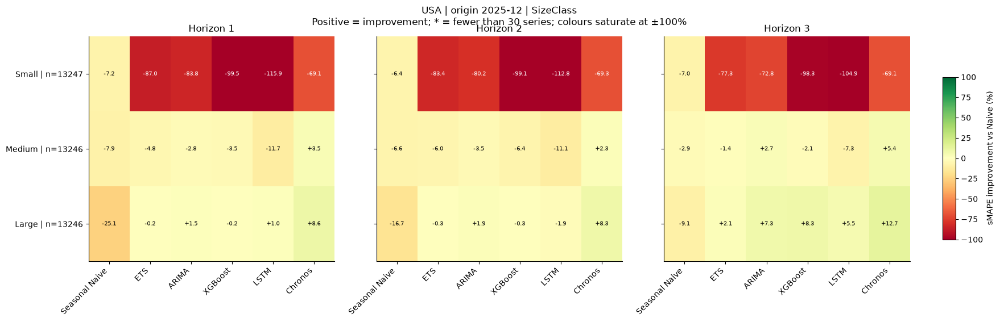

In [5]:
ALTERNATIVES=[m for m in MODELS if m!='Naive']
GROUP_FILENAMES={'HSChapter':'hs','Flow':'flow','SizeClass':'size'}
def plot_groups(country,origin,group_type):
    data=group_metrics.loc[group_metrics.Country.eq(country)&group_metrics.Origin.eq(origin)&
                            group_metrics.GroupType.eq(group_type)]
    labels=sorted(data.Group.unique())
    if group_type=='SizeClass':labels=[x for x in ['Small','Medium','Large'] if x in labels]
    counts=data.loc[data.Model.eq('Naive')].groupby('Group')['N Series'].first()
    height=max(5.5,.22*len(labels)+2.5)
    fig,axes=plt.subplots(1,len(HORIZONS),figsize=(19,height),sharey=True)
    cmap=plt.get_cmap('RdYlGn').copy();cmap.set_bad('#e3e3e3')
    for ax,h in zip(axes,HORIZONS):
        group=data.loc[data.Horizon.eq(h)]
        values=group.pivot(index='Group',columns='Model',values='sMAPE (%) improvement (%)').reindex(
            index=labels,columns=ALTERNATIVES).to_numpy()
        image=ax.imshow(np.ma.masked_invalid(values),cmap=cmap,vmin=-100,vmax=100,aspect='auto')
        ax.grid(False);ax.set_title(f'Horizon {h}')
        ax.set_xticks(range(len(ALTERNATIVES)),ALTERNATIVES,rotation=45,ha='right')
        ax.set_yticks(range(len(labels)),[
            f"{label} | n={int(counts[label])}{'*' if counts[label]<MIN_GROUP_SERIES else ''}" for label in labels])
        for row in range(len(labels)):
            for col in range(len(ALTERNATIVES)):
                value=values[row,col]
                text='N/A' if not np.isfinite(value) else f'{value:+.1f}'
                colour='white' if np.isfinite(value) and abs(value)>65 else 'black'
                ax.text(col,row,text,ha='center',va='center',fontsize=7.5,color=colour)
    fig.suptitle(f'{country} | origin {origin:%Y-%m} | {group_type}\n'
                 'Positive = improvement; * = fewer than 30 series; colours saturate at ±100%')
    fig.subplots_adjust(left=.12,right=.88,bottom=.16,top=.88,wspace=.17)
    colour_axis=fig.add_axes([.91,.23,.012,.52])
    fig.colorbar(image,cax=colour_axis,label='sMAPE improvement vs Naive (%)')
    filename=f'relative_accuracy_by_{GROUP_FILENAMES[group_type]}_{COUNTRY_PREFIXES[country]}_{origin:%Y-%m}.png'
    fig.savefig(OUTPUT_DIR/filename,dpi=150,bbox_inches='tight')
    display(fig);plt.close(fig)
for country in COUNTRIES:
    for origin in ORIGINS:
        for group_type in GROUP_COLUMNS:
            plot_groups(country,origin,group_type)

## 6. Descriptive Summary

Identify primary-metric winners separately at each origin and horizon. The grouped tables show where an overall model advantage is concentrated or reversed. Three separated origins provide additional evidence, but do not establish performance across all seasons or independent statistical significance.

Size and chapter interpretations remain conditional on the fixed pre-evaluation cohort. Chronos uses broad pretrained weights rather than trade-specific fitting; its checkpoint predates the evaluation period, while historical pretraining overlap is unverified. Native statistical negatives and recorded fallbacks remain visible in the comparison.

In [6]:
winners=origin_metrics.loc[origin_metrics.groupby(['Country','Origin','Horizon'])['sMAPE (%)'].idxmin(),
    ['Country','Origin','Horizon','Model','sMAPE (%)','N Series']]
display(winners.sort_values(['Country','Origin','Horizon']))
print('Saved primary metrics: origin_metrics.csv and group_metrics.csv')
print('Saved two overall figures plus 27 country-origin group figures.')
print('Directory:',OUTPUT_DIR)

,Country,Origin,Horizon,Model,sMAPE (%),N Series
99,Slovakia,2025-04-01,1,Naive,68.908687,31328
100,Slovakia,2025-04-01,2,Naive,70.700069,31328
101,Slovakia,2025-04-01,3,Naive,73.102811,31328
102,Slovakia,2025-08-01,1,Naive,68.341801,31328
103,Slovakia,2025-08-01,2,Naive,72.019394,31328
104,Slovakia,2025-08-01,3,Naive,127.754297,31328
105,Slovakia,2025-12-01,1,Naive,70.412384,31328
106,Slovakia,2025-12-01,2,Naive,73.236152,31328
116,Slovakia,2025-12-01,3,Seasonal Naive,76.620248,31328
36,South Korea,2025-04-01,1,Naive,69.094024,28231


Saved primary metrics: origin_metrics.csv and group_metrics.csv
Saved two overall figures plus 27 country-origin group figures.
Directory: c:\Transfer\InterdisciplinaryProject\results\extended_benchmark
